In [2]:
%pip install sherpa-onnx soundfile


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import soundfile as sf

folder = Path.home() / ".cache" / "asr-study" / "sensevoice"
audio_file = folder / "test_wavs" / "ko.wav"

waveform, sample_rate = sf.read(audio_file, dtype="float32")

print("파형 모양:", waveform.shape)
print("샘플링 주파수:", sample_rate, "Hz")
print("음성 길이:", round(len(waveform) / sample_rate, 2), "초")

파형 모양: (73728,)
샘플링 주파수: 16000 Hz
음성 길이: 4.61 초


In [4]:
import sherpa_onnx

# 학습된 모델과 토큰 목록을 읽어 인식기를 준비해요.
recognizer = sherpa_onnx.OfflineRecognizer.from_sense_voice(
    model=str(folder / "model.int8.onnx"),
    tokens=str(folder / "tokens.txt"),
    language="ko",
    provider="cpu",
)

# 첫 셀에서 읽은 음성 한 건을 인식해요.
stream = recognizer.create_stream()
stream.accept_waveform(sample_rate, waveform)
recognizer.decode_stream(stream)

print("인식 결과:", stream.result.text)

인식 결과: 조금만 생각을 하면서 살면 훨씬 편할 거야


In [5]:
%pip install jiwer


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
from jiwer import cer, wer

reference = "조금만 생각을 하면서 살면 훨씬 편할 거야"
recognized = stream.result.text.strip()

def show_score(answer):
    print("기준 문장:", reference)
    print("채점할 문장:", answer)
    print("글자 오류율:", f"{cer(reference.replace(' ', ''), answer.replace(' ', '')):.1%}")
    print("어절 오류율:", f"{wer(reference, answer):.1%}")

show_score(recognized)

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
채점할 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
글자 오류율: 0.0%
어절 오류율: 0.0%


In [7]:
practice = recognized.replace("조금만", "조금", 1)
show_score(practice)

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
채점할 문장: 조금 생각을 하면서 살면 훨씬 편할 거야
글자 오류율: 5.9%
어절 오류율: 14.3%


In [8]:
import time

audio_seconds = len(waveform) / sample_rate

start = time.perf_counter()  # 초시계 시작
speed_stream = recognizer.create_stream()
speed_stream.accept_waveform(sample_rate, waveform)
recognizer.decode_stream(speed_stream)
text = speed_stream.result.text
elapsed = time.perf_counter() - start  # 걸린 시간

rtf = elapsed / audio_seconds

print("인식 결과:", text)
print(f"음성 길이: {audio_seconds:.3f}초")
print(f"인식 시간: {elapsed:.3f}초")
print(f"RTF: {elapsed:.3f} ÷ {audio_seconds:.3f} = {rtf:.3f}")

인식 결과: 조금만 생각을 하면서 살면 훨씬 편할 거야
음성 길이: 4.608초
인식 시간: 0.651초
RTF: 0.651 ÷ 4.608 = 0.141


In [9]:
import numpy as np

rng = np.random.default_rng(42)
noise = rng.normal(0, 1, size=waveform.shape).astype("float32")

noise_level = 1.0
noisy_waveform = waveform + noise_level * waveform.std() * noise

print("원본 샘플 수:", len(waveform))
print("잡음 섞인 샘플 수:", len(noisy_waveform))

원본 샘플 수: 73728
잡음 섞인 샘플 수: 73728


In [10]:
noisy_stream = recognizer.create_stream()
noisy_stream.accept_waveform(sample_rate, noisy_waveform)
recognizer.decode_stream(noisy_stream)
noisy_text = noisy_stream.result.text

print("원본 음성:", recognized)
print("잡음 음성:", noisy_text)
print()
show_score(noisy_text)

원본 음성: 조금만 생각을 하면서 살면 훨씬 편할 거야
잡음 음성: 누금만 생각을 하면서 되면 훨씬 편할까

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
채점할 문장: 누금만 생각을 하면서 되면 훨씬 편할까
글자 오류율: 23.5%
어절 오류율: 57.1%


In [11]:
import jiwer

result = jiwer.process_words(reference, noisy_text)

print("기준 문장:", reference)
print("잡음 음성의 인식 결과:", noisy_text)
print()
print("다른 어절로 바뀜:", result.substitutions)
print("기준에 있던 어절이 빠짐:", result.deletions)
print("기준에 없던 어절이 추가됨:", result.insertions)

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
잡음 음성의 인식 결과: 누금만 생각을 하면서 되면 훨씬 편할까

다른 어절로 바뀜: 3
기준에 있던 어절이 빠짐: 1
기준에 없던 어절이 추가됨: 0


In [ ]:

# CER-> 글자 단위 오류율, WER-> 단어 단위 오류율

import numpy as np
from jiwer import cer, wer

rng = np.random.default_rng(42)
noise = rng.normal(0, 1, size=waveform.shape).astype("float32")
voice_scale = waveform.std()

results = []  # 반복을 시작하기 전에 딱 한 번 빈 목록을 만들어요

for level in [0.00, 0.25, 0.50, 0.75, 1.00, 1.25, 1.50]:
    noisy_wave = waveform + level * voice_scale * noise

    stream = recognizer.create_stream()
    stream.accept_waveform(sample_rate, noisy_wave)
    recognizer.decode_stream(stream)
    text = stream.result.text.strip()

    char_error = cer(reference.replace(" ", ""), text.replace(" ", ""))
    word_error = wer(reference, text)
    results.append((level, char_error * 100, word_error * 100))
    print(f"{level:.2f} | CER {char_error:.1%} | WER {word_error:.1%} | {text}")

print("저장된 결과:", len(results), "개")

0.00 | CER 0.0% | WER 0.0% | 조금만 생각을 하면서 살면 훨씬 편할 거야
0.25 | CER 0.0% | WER 0.0% | 조금만 생각을 하면서 살면 훨씬 편할 거야
0.50 | CER 23.5% | WER 42.9% | 조금만 생각을 하면서 갈면 훨씬 큰날까야
0.75 | CER 23.5% | WER 42.9% | 조금만 생각을 하면서 되면 훨씬 그할까
1.00 | CER 23.5% | WER 57.1% | 누금만 생각을 하면서 되면 훨씬 편할까
1.25 | CER 47.1% | WER 71.4% | 누금만 생각을 하면서 저는 편까요
1.50 | CER 52.9% | WER 71.4% | 누금만 생각을 하면서 저는
저장된 결과: 7 개


In [13]:
#%pip install matplotlib

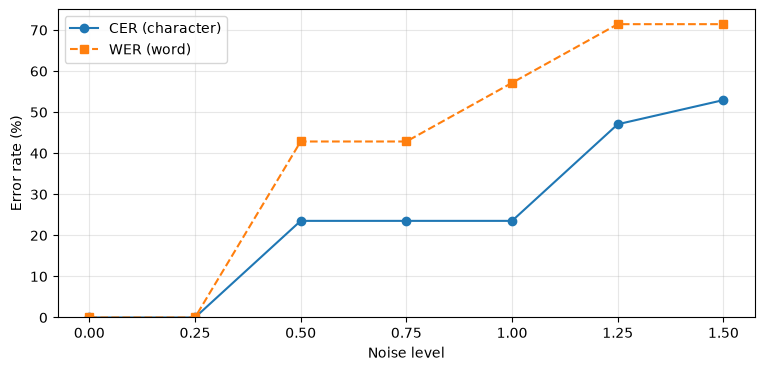

In [16]:
import matplotlib.pyplot as plt

# 저장한 표를 세로로 읽어서 세 열로 나눠요.
levels, cer_values, wer_values = zip(*results)

plt.figure(figsize=(9, 4))
plt.plot(levels, cer_values, "o-", label="CER (character)")
plt.plot(levels, wer_values, "s--", label="WER (word)")

plt.xlabel("Noise level")
plt.ylabel("Error rate (%)")
plt.xticks(levels)
plt.ylim(bottom=0)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [17]:
from jiwer import cer, wer

def recognize(wave):
    stream = recognizer.create_stream()
    stream.accept_waveform(sample_rate, wave)
    recognizer.decode_stream(stream)
    return stream.result.text.strip()

before_wave = noisy_waveform.copy()
before_text = recognize(before_wave)

print("처리 전 문장:", before_text)
print("처리 전 WER:", f"{wer(reference, before_text):.1%}")

처리 전 문장: 누금만 생각을 하면서 되면 훨씬 편할까
처리 전 WER: 57.1%


In [18]:
import numpy as np

weights = np.array([1/3, 1/3, 1/3], dtype=np.float32)
after_wave = np.convolve(before_wave, weights, mode="same")

print("처리 전 샘플 수:", len(before_wave))
print("처리 후 샘플 수:", len(after_wave))

처리 전 샘플 수: 73728
처리 후 샘플 수: 73728


In [19]:
after_text = recognize(after_wave)

print("기준 문장:", reference)
print()

for label, text in [("처리 전", before_text), ("처리 후", after_text)]:
    char_error = cer(reference.replace(" ", ""), text.replace(" ", ""))
    word_error = wer(reference, text)

    print(f"{label} | CER {char_error:.1%} | WER {word_error:.1%}")
    print(text)

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야

처리 전 | CER 23.5% | WER 57.1%
누금만 생각을 하면서 되면 훨씬 편할까
처리 후 | CER 35.3% | WER 71.4%
누금만 생각을 하는데 보면 훨씬 편할까


In [21]:
import numpy as np
from scipy.signal import stft, istft

# 400개씩 보고 160개씩 이동하므로 이웃한 프레임은 240개가 겹쳐요.
_, _, spectrum = stft(before_wave, fs=sample_rate, nperseg=400, noverlap=240)
magnitude = np.abs(spectrum)

# 각 프레임의 세기를 구하고, 가장 조용한 20%를 골라요.
frame_power = (magnitude ** 2).mean(axis=0)
quiet_frames = frame_power <= np.quantile(frame_power, 0.20)

# 조용한 프레임들의 평균을 내서 주파수별 잡음 크기를 추정해요.
noise_profile = magnitude[:, quiet_frames].mean(axis=1, keepdims=True)

print("전체 프레임 수:", magnitude.shape[1])
print("잡음 추정에 쓴 프레임 수:", quiet_frames.sum())

전체 프레임 수: 462
잡음 추정에 쓴 프레임 수: 93


In [22]:
gain = 1 - noise_profile / np.maximum(magnitude, 1e-10)
gain = np.clip(gain, 0.10, 1.0)
cleaned_spectrum = spectrum * gain

_, spectral_wave = istft(cleaned_spectrum, fs=sample_rate, nperseg=400, noverlap=240)
spectral_wave = spectral_wave[:len(before_wave)].astype(np.float32)

print("처리 전후 샘플 수가 같은가?", len(before_wave) == len(spectral_wave))

처리 전후 샘플 수가 같은가? True
